# Ridge regression 

**Pipeline:** `log10(P(k))` → standardize → Ridge regression
**Protocol:**
- For every level (1, 2, 3), the data is already split into 5 folds + a test set.
- α is chosen by 5-fold cross-validation: train on 4 folds, validate on the 5th, rotate.
- The final model is trained on all 5 folds and evaluated **once** on the test set.
- Metrics: MAE and RMSE, separately for Ωm and σ8, plus predicted-vs-true plots.

In [1]:
from pathlib import Path
import csv

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import fetch
from fetch import GetSpectrumTrainFold, GetSpectrumTestData

DATA_ROOT = Path(fetch.__file__).resolve().parent / "powerspectrum"

LEVELS = [1, 2, 3]
N_FOLDS = 5
ALPHAS = np.logspace(-6, 4, 41)          # candidate regularization strengths
PARAM_NAMES = ["Omega_m", "sigma_8"]      # for files and printing
PARAM_TEX = [r"$\Omega_m$", r"$\sigma_8$"]  # for plot labels

OUT_DIR = Path("results/ridge")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the data

In [ ]:
def load_level(level):
    # Each 'fold' is one fifth of the non-test data. Together the 5 folds are the full training set.
    folds = []
    for k in range(1, N_FOLDS + 1):
        X, y = GetSpectrumTrainFold(level, k)
        folds.append((np.asarray(X, dtype=np.float64), np.asarray(y, dtype=np.float64)))
    X_test, y_test = GetSpectrumTestData(level)
    return folds, np.asarray(X_test, dtype=np.float64), np.asarray(y_test, dtype=np.float64)


data = {level: load_level(level) for level in LEVELS}

## 2. Sanity checks

- `log10` needs every P(k) value to be positive.
- Several samples share the same cosmology (several maps per simulation). If the same cosmology appeared in both a training fold and the test set, the test score would be too optimistic, so we check that the splits share no cosmologies.

In [3]:
def cosmologies(y):
    return {tuple(np.round(row, 6)) for row in y}


for level, (folds, X_test, y_test) in data.items():
    X_all = np.concatenate([X for X, _ in folds] + [X_test])
    groups = [cosmologies(y) for _, y in folds] + [cosmologies(y_test)]
    names = [f"fold{k}" for k in range(1, N_FOLDS + 1)] + ["test"]

    print(f"Level {level}")
    print(f"  samples per fold: {[len(X) for X, _ in folds]}, test: {len(X_test)}, k-bins: {X_all.shape[1]}")
    print(f"  cosmologies per fold: {[len(g) for g in groups[:-1]]}, test: {len(groups[-1])}")
    print(f"  min P(k) = {X_all.min():.3g}   NaN present: {np.isnan(X_all).any()}")

    overlaps = [(names[i], names[j], len(groups[i] & groups[j]))
                for i in range(len(groups)) for j in range(i + 1, len(groups))
                if groups[i] & groups[j]]
    print("  cosmologies shared between splits:", overlaps if overlaps else "none (no leakage)")

    if X_all.min() <= 0:
        print("  WARNING: non-positive P(k) values, log10 will fail. Tell Aman.")

Level 1
  samples per fold: [165, 165, 165, 165, 150], test: 195, k-bins: 50
  cosmologies per fold: [11, 11, 11, 11, 10], test: 13
  min P(k) = 0.00806   NaN present: False
  cosmologies shared between splits: none (no leakage)
Level 2
  samples per fold: [810, 795, 795, 795, 795], test: 1005, k-bins: 50
  cosmologies per fold: [54, 53, 53, 53, 53], test: 67
  min P(k) = 0.00613   NaN present: False
  cosmologies shared between splits: none (no leakage)
Level 3
  samples per fold: [1440, 1440, 1440, 1440, 1440], test: 1800, k-bins: 50
  cosmologies per fold: [96, 96, 96, 96, 96], test: 120
  min P(k) = 0.004   NaN present: False
  cosmologies shared between splits: none (no leakage)


## 3. Model and cross-validation

The `Pipeline` makes sure the scaler is fitted on the training folds only, so no information from the validation fold leaks in.

In [4]:
def make_model(alpha):
    # alpha can be one number or an array [alpha_Omega_m, alpha_sigma_8]
    return make_pipeline(
        FunctionTransformer(np.log10),
        StandardScaler(),
        Ridge(alpha=alpha),
    )


def cross_validate(folds, alphas):
    # Returns RMSE and MAE arrays of shape (n_folds, n_alphas, 2 parameters).
    rmse = np.zeros((len(folds), len(alphas), 2))
    mae = np.zeros_like(rmse)
    for k in range(len(folds)):
        X_val, y_val = folds[k]
        X_tr = np.concatenate([X for i, (X, _) in enumerate(folds) if i != k])
        y_tr = np.concatenate([y for i, (_, y) in enumerate(folds) if i != k])
        for a, alpha in enumerate(alphas):
            pred = make_model(alpha).fit(X_tr, y_tr).predict(X_val)
            rmse[k, a] = np.sqrt(((pred - y_val) ** 2).mean(axis=0))
            mae[k, a] = np.abs(pred - y_val).mean(axis=0)
    return rmse, mae


cv = {}
for level, (folds, _, _) in data.items():
    rmse, mae = cross_validate(folds, ALPHAS)
    best_idx = rmse.mean(axis=0).argmin(axis=0)   # best alpha index for each parameter
    cv[level] = dict(rmse=rmse, mae=mae, best_idx=best_idx, best_alpha=ALPHAS[best_idx])

    print(f"Level {level}")
    for t, name in enumerate(PARAM_NAMES):
        i = best_idx[t]
        print(f"  {name:8s} best alpha = {ALPHAS[i]:.3g}   "
              f"CV RMSE = {rmse[:, i, t].mean():.4f} ± {rmse[:, i, t].std():.4f}   "
              f"CV MAE = {mae[:, i, t].mean():.4f} ± {mae[:, i, t].std():.4f}")
        if i in (0, len(ALPHAS) - 1):
            print("    WARNING: best alpha is at the edge of the grid, widen ALPHAS.")

Level 1
  Omega_m  best alpha = 100   CV RMSE = 0.0953 ± 0.0157   CV MAE = 0.0816 ± 0.0171
  sigma_8  best alpha = 100   CV RMSE = 0.0977 ± 0.0170   CV MAE = 0.0826 ± 0.0155
Level 2
  Omega_m  best alpha = 100   CV RMSE = 0.0896 ± 0.0055   CV MAE = 0.0743 ± 0.0055
  sigma_8  best alpha = 178   CV RMSE = 0.0956 ± 0.0045   CV MAE = 0.0792 ± 0.0047
Level 3
  Omega_m  best alpha = 178   CV RMSE = 0.0919 ± 0.0034   CV MAE = 0.0755 ± 0.0027
  sigma_8  best alpha = 316   CV RMSE = 0.0989 ± 0.0043   CV MAE = 0.0832 ± 0.0031


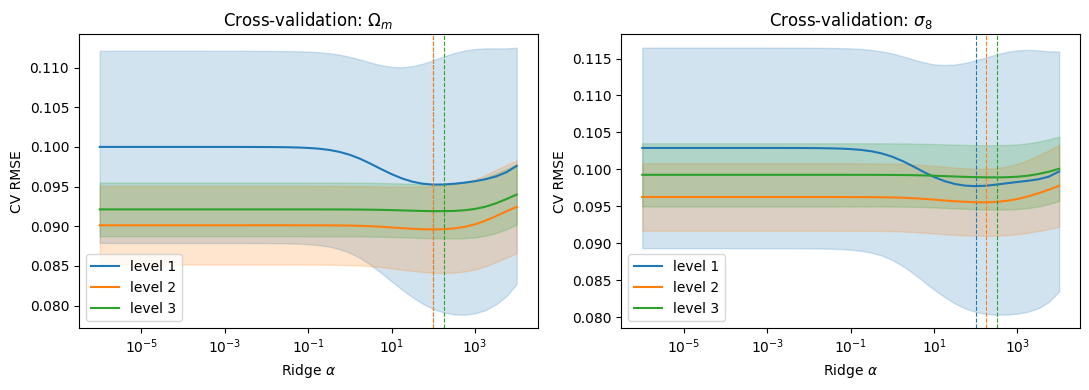

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for t, ax in enumerate(axes):
    for level in LEVELS:
        mean = cv[level]["rmse"][:, :, t].mean(axis=0)
        std = cv[level]["rmse"][:, :, t].std(axis=0)
        line, = ax.plot(ALPHAS, mean, label=f"level {level}")
        ax.fill_between(ALPHAS, mean - std, mean + std, alpha=0.2, color=line.get_color())
        ax.axvline(cv[level]["best_alpha"][t], ls="--", lw=0.8, color=line.get_color())
    ax.set_xscale("log")
    ax.set_xlabel(r"Ridge $\alpha$")
    ax.set_ylabel("CV RMSE")
    ax.set_title(f"Cross-validation: {PARAM_TEX[t]}")
    ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "cv_curves.png", dpi=150)
plt.show()

## 4. Final evaluation on the test set

Train on all 5 folds with the chosen α, then evaluate once on the test set. A trivial baseline that always predicts the training mean is included as a reference: Ridge must beat it to be learning anything.

Metrics are reported two ways, matching the MLP branch:
- **per map**: every one of the 15 maps of a simulation is scored separately;
- **per simulation**: the 15 predictions of each simulation are averaged first, which removes much of the map-to-map noise.

In [6]:
def load_test_simulation_ids(level, y_test):
    path = DATA_ROOT / f"level{level}" / "test" / "simulation_ids.npy"
    if path.exists():
        return np.load(path, allow_pickle=False)
    # fallback: every simulation has its own unique (Omega_m, sigma_8) pair
    _, ids = np.unique(np.round(y_test, 6), axis=0, return_inverse=True)
    return ids.ravel()


def simulation_average(pred, y, sim_ids):
    ids = np.unique(sim_ids)
    pred_sim = np.array([pred[sim_ids == i].mean(axis=0) for i in ids])
    y_sim = np.array([y[sim_ids == i][0] for i in ids])
    return pred_sim, y_sim


rows = []
predictions = {}

for level, (folds, X_test, y_test) in data.items():
    X_tr = np.concatenate([X for X, _ in folds])
    y_tr = np.concatenate([y for _, y in folds])

    model = make_model(cv[level]["best_alpha"]).fit(X_tr, y_tr)
    pred = model.predict(X_test)
    mean_pred = np.tile(y_tr.mean(axis=0), (len(y_test), 1))
    predictions[level] = pred
    np.save(OUT_DIR / f"test_predictions_level{level}.npy", pred)

    sim_ids = load_test_simulation_ids(level, y_test)
    pred_sim, y_sim = simulation_average(pred, y_test, sim_ids)

    for t, name in enumerate(PARAM_NAMES):
        rows.append({
            "level": level,
            "parameter": name,
            "n_train": len(X_tr),
            "alpha": cv[level]["best_alpha"][t],
            "MAE": mean_absolute_error(y_test[:, t], pred[:, t]),
            "RMSE": np.sqrt(mean_squared_error(y_test[:, t], pred[:, t])),
            "R2": r2_score(y_test[:, t], pred[:, t]),
            "sim_MAE": mean_absolute_error(y_sim[:, t], pred_sim[:, t]),
            "sim_RMSE": np.sqrt(mean_squared_error(y_sim[:, t], pred_sim[:, t])),
            "sim_R2": r2_score(y_sim[:, t], pred_sim[:, t]),
            "baseline_RMSE": np.sqrt(mean_squared_error(y_test[:, t], mean_pred[:, t])),
        })

print(f"{'':24} {'---------- per map ----------':>30}   {'------- per simulation -------':>30}")
print(f"{'level':>5} {'param':>8} {'alpha':>9} {'MAE':>9} {'RMSE':>9} {'R2':>9}   {'MAE':>9} {'RMSE':>9} {'R2':>9}   {'mean-pred RMSE':>14}")
for r in rows:
    print(f"{r['level']:>5} {r['parameter']:>8} {r['alpha']:>9.3g} "
          f"{r['MAE']:>9.4f} {r['RMSE']:>9.4f} {r['R2']:>9.3f}   "
          f"{r['sim_MAE']:>9.4f} {r['sim_RMSE']:>9.4f} {r['sim_R2']:>9.3f}   {r['baseline_RMSE']:>14.4f}")

with open(OUT_DIR / "ridge_results.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)
print(f"\nSaved to {OUT_DIR / 'ridge_results.csv'}")

                          ---------- per map ----------   ------- per simulation -------
level    param     alpha       MAE      RMSE        R2         MAE      RMSE        R2   mean-pred RMSE
    1  Omega_m       100    0.1124    0.1266     0.287      0.1116    0.1229     0.328           0.1500
    1  sigma_8       100    0.0924    0.1072    -0.037      0.0876    0.0996     0.106           0.1054
    2  Omega_m       100    0.0735    0.0869     0.414      0.0678    0.0788     0.518           0.1138
    2  sigma_8       178    0.0744    0.0934     0.279      0.0690    0.0864     0.383           0.1102
    3  Omega_m       178    0.0747    0.0925     0.391      0.0675    0.0827     0.513           0.1198
    3  sigma_8       316    0.0832    0.1000     0.196      0.0780    0.0940     0.289           0.1124

Saved to results\ridge\ridge_results.csv


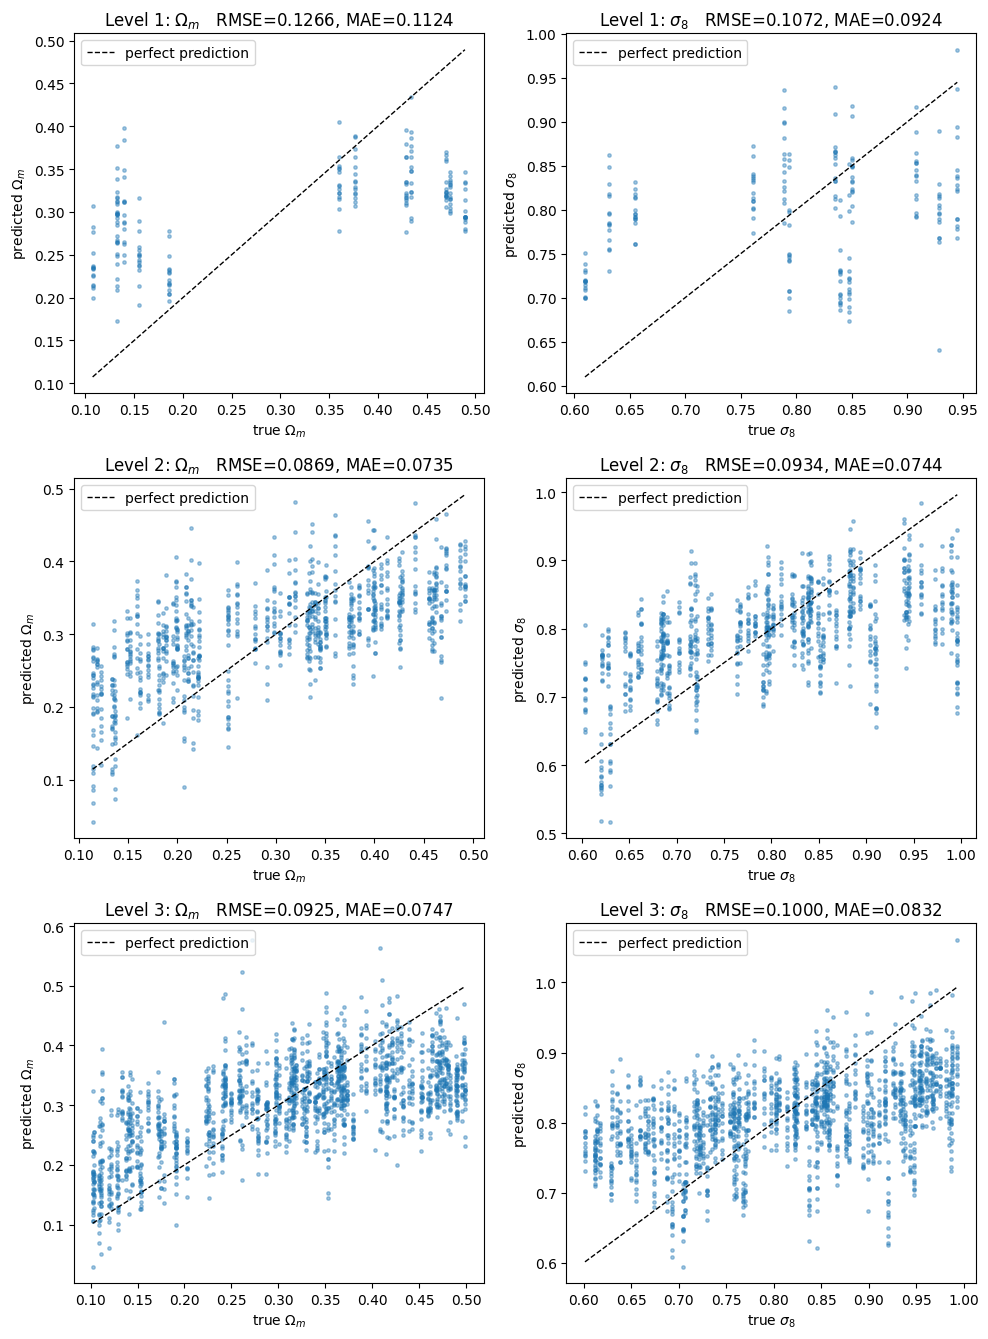

In [7]:
fig, axes = plt.subplots(len(LEVELS), 2, figsize=(10, 4.5 * len(LEVELS)))
for row, level in enumerate(LEVELS):
    y_test = data[level][2]
    pred = predictions[level]
    for t in range(2):
        ax = axes[row, t]
        lo, hi = y_test[:, t].min(), y_test[:, t].max()
        ax.scatter(y_test[:, t], pred[:, t], s=6, alpha=0.4)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="perfect prediction")
        r = next(r for r in rows if r["level"] == level and r["parameter"] == PARAM_NAMES[t])
        ax.set_title(f"Level {level}: {PARAM_TEX[t]}   RMSE={r['RMSE']:.4f}, MAE={r['MAE']:.4f}")
        ax.set_xlabel(f"true {PARAM_TEX[t]}")
        ax.set_ylabel(f"predicted {PARAM_TEX[t]}")
        ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(OUT_DIR / "pred_vs_true.png", dpi=150)
plt.show()

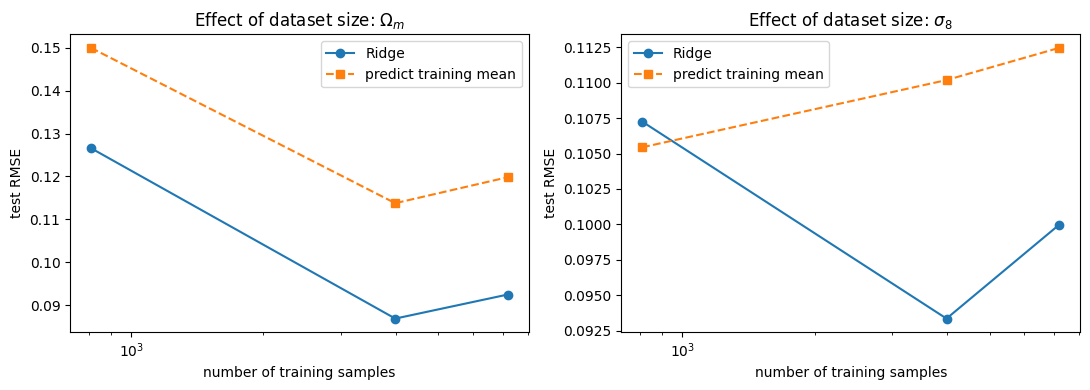

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for t, ax in enumerate(axes):
    sel = [r for r in rows if r["parameter"] == PARAM_NAMES[t]]
    n = [r["n_train"] for r in sel]
    ax.plot(n, [r["RMSE"] for r in sel], "o-", label="Ridge")
    ax.plot(n, [r["baseline_RMSE"] for r in sel], "s--", label="predict training mean")
    ax.set_xscale("log")
    ax.set_xlabel("number of training samples")
    ax.set_ylabel("test RMSE")
    ax.set_title(f"Effect of dataset size: {PARAM_TEX[t]}")
    ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "rmse_vs_train_size.png", dpi=150)
plt.show()

## Outputs

All saved in `results/ridge/`:
- `ridge_results.csv`: test MAE, RMSE, R² (per map and per simulation) and chosen α for every level and parameter
- `test_predictions_level{1,2,3}.npy`: test-set predictions, columns (Ωm, σ8), for combined comparison plots
- `cv_curves.png`, `pred_vs_true.png`, `rmse_vs_train_size.png`